In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import os
import json

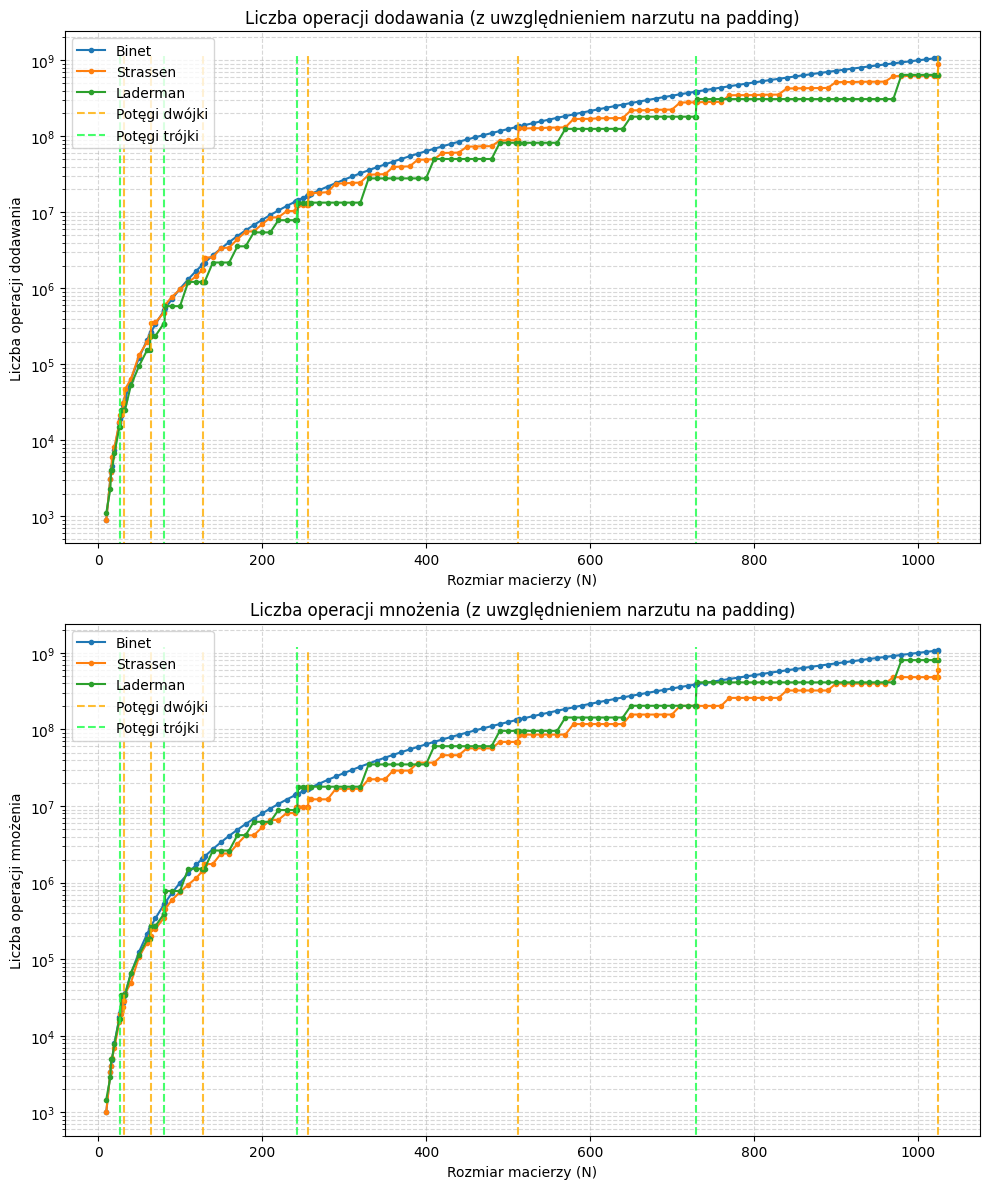

In [2]:
# Wczytanie zebranych danych
binet_operation_results = pd.read_csv('operation_comparison/Binet_operation_count.csv')
strassen_operation_results = pd.read_csv('operation_comparison/Strassen_operation_count.csv')
laderman_operation_results = pd.read_csv('operation_comparison/Laderman_operation_count.csv')

# Utworzenie dwóch wykresów ułożonych pionowo
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12))
power_of_two_sizes = [2**i for i in range(5, 11)]  # Rozmiary macierzy będące potęgami dwójki od 2 do 1024
power_of_three_sizes = [3**i for i in range(3, 7)]  # Rozmiary macierzy będące potęgami trójki od 3 do 729


ax1.plot(binet_operation_results['Size'], binet_operation_results['Additions'], label='Binet', marker='.', linestyle='-')
ax1.plot(strassen_operation_results['Size'], strassen_operation_results['Additions'], label='Strassen', marker='.', linestyle='-')
ax1.plot(laderman_operation_results['Size'], laderman_operation_results['Additions'], label='Laderman', marker='.', linestyle='-')
ax1.vlines(power_of_two_sizes, ymin=ax1.get_ylim()[0], ymax=ax1.get_ylim()[1], colors='#FFAE00',label='Potęgi dwójki', linestyles='dashed', alpha=0.8)
ax1.vlines(power_of_three_sizes, ymin=ax1.get_ylim()[0], ymax=ax1.get_ylim()[1], colors='#17FF46',label='Potęgi trójki', linestyles='dashed', alpha=0.8)
ax1.set_title('Liczba operacji dodawania (z uwzględnieniem narzutu na padding)')
ax1.set_xlabel('Rozmiar macierzy (N)')
ax1.set_ylabel('Liczba operacji dodawania')
ax1.set_yscale('log') # Skala logarytmiczna
ax1.grid(True, which="both", ls="--", alpha=0.5)
ax1.legend()


ax2.plot(binet_operation_results['Size'], binet_operation_results['Multiplications'], label='Binet', marker='.', linestyle='-')
ax2.plot(strassen_operation_results['Size'], strassen_operation_results['Multiplications'], label='Strassen', marker='.', linestyle='-')
ax2.plot(laderman_operation_results['Size'], laderman_operation_results['Multiplications'], label='Laderman', marker='.', linestyle='-')
ax2.vlines(power_of_two_sizes, ymin=ax2.get_ylim()[0], ymax=ax2.get_ylim()[1], colors='#FFAE00',label='Potęgi dwójki', linestyles='dashed', alpha=0.8)
ax2.vlines(power_of_three_sizes, ymin=ax2.get_ylim()[0], ymax=ax2.get_ylim()[1], colors='#17FF46',label='Potęgi trójki', linestyles='dashed', alpha=0.8)
ax2.set_title('Liczba operacji mnożenia (z uwzględnieniem narzutu na padding)')
ax2.set_xlabel('Rozmiar macierzy (N)')
ax2.set_ylabel('Liczba operacji mnożenia')
ax2.set_yscale('log') # Skala logarytmiczna
ax2.grid(True, which="both", ls="--", alpha=0.5)
ax2.legend()





plt.tight_layout()
plt.savefig('liczba_operacji.png', dpi=300) # Zapis do pliku w wysokiej rozdzielczości
plt.show()

In [3]:
from pathlib import Path

# Ustawienie katalogu na folder skryptu
os.chdir(Path(os.getcwd()).parent.parent)

In [6]:
base_path = "target/criterion/Matrix_multiplication_comparison"
data = []

print(os.getcwd())
# 1. Przeszukiwanie folderów algorytmów (Binet, Strassen, Laderman)
for algorytm in os.listdir(base_path):
    algo_path = os.path.join(base_path, algorytm)
    
    # Pomijamy pliki systemowe i folder z raportami HTML
    if not os.path.isdir(algo_path) or algorytm == "report":
        continue
        
    # 2. Przeszukiwanie folderów z rozmiarami N (np. 10, 20, 256)
    for rozmiar_str in os.listdir(algo_path):
        if not rozmiar_str.isdigit():
            continue
            
        json_path = os.path.join(algo_path, rozmiar_str, "new", "estimates.json")
        
        # 3. Odczytanie czasu z pliku JSON
        if os.path.exists(json_path):
            with open(json_path, 'r') as f:
                est = json.load(f)
                # Criterion domyślnie zapisuje czas (point_estimate) w nanosekundach.
                # Dzielimy przez 1_000_000, aby otrzymać wynik w czytelnych milisekundach.
                czas_ms = est["mean"]["point_estimate"] / 1_000_000.0
                data.append({"Algorytm": algorytm, "N": int(rozmiar_str), "Czas_ms": czas_ms})
df = pd.DataFrame(data)

#Pivotowanie tabeli - żeby każdy algorytm miał własną kolumnę, a wierszem był rozmiar N
df_wykres = df.pivot(index="N", columns="Algorytm", values="Czas_ms").reset_index()

# Sortowanie po rozmiarze N rosnąco
df_wykres = df_wykres.sort_values(by="N")



# --- Opcjonalnie: Szybkie wygenerowanie wykresu prosto z tych danych ---
plt.figure(figsize=(10, 6))
for alg in ["Binet", "Strassen", "Laderman", "Dot-product"]:
    # dropna() zabezpiecza nas na wypadek braku jakiegoś pojedynczego pomiaru
    plt.plot(df_wykres["N"], df_wykres[alg], label=alg, marker='.', linestyle='-')

ax = plt.gca()

plt.vlines(power_of_two_sizes, ymin=ax.get_ylim()[0], ymax=ax.get_ylim()[1], colors='#FFAE00',label='Potęgi dwójki', linestyles='dashed', alpha=0.8)
plt.vlines(power_of_three_sizes, ymin=ax.get_ylim()[0], ymax=ax.get_ylim()[1], colors='#17FF46',label='Potęgi trójki', linestyles='dashed', alpha=0.8)
plt.yscale('log') # Skala logarytmiczna dla osi Y pokaże uskoki
plt.title('Porównanie czasów wykonywania algorytmów mnożenia macierzy (Binet, Strassen, Laderman, Dot-product)')
plt.xlabel('Rozmiar macierzy (N)')
plt.ylabel('Średni czas (ms)')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig('z1/src/porównanie_czasów.png', dpi=300)
print("Zapisano wykres jako wykres_czasu_criterion.png")
plt.show()

C:\Users\matis\RustroverProjects\Algorytmy_Macierzowe


FileNotFoundError: [WinError 3] System nie może odnaleźć określonej ścieżki: 'target/criterion/Matrix_multiplication_comparison'

In [ ]:
# 1. Wczytanie tabeli z czasami (wygenerowanej z JSON-ów Criteriona)
df_czas = df
algorytmy = ["Binet", "Strassen", "Laderman"]

for alg in algorytmy:
    # 2. Wczytanie tabeli z liczbą operacji dla danego algorytmu
    sciezka_operacje = f"z1/src/operation_comparison/{alg}_operation_count.csv"
    try:
        df_op = pd.read_csv(sciezka_operacje)
    except FileNotFoundError:
        print(f"Brak pliku {sciezka_operacje}. Pomijam {alg}.")
        continue
    
# 2. Wycięcie czasów tylko dla aktualnego algorytmu
    df_czas_alg = df_czas[df_czas['Algorytm'] == alg]
    
    # 3. Połączenie danych operacji z czasem
    df_merged = pd.merge(df_op, df_czas_alg[['N', 'Czas_ms']], left_on='Size', right_on='N', how='inner')
    
    fig, ax1 = plt.subplots(figsize=(10, 6))
    
    # --- OŚ LEWA (Liczba operacji) ---
    color_add = 'tab:blue'
    color_mult = 'tab:orange'
    ax1.set_xlabel('Rozmiar macierzy (N)', fontsize=12)
    ax1.set_ylabel('Liczba operacji', color='black', fontsize=12)
    
    line1 = ax1.plot(df_merged['N'], df_merged['Additions'], color=color_add, label='Dodawania', marker='.', markersize=6)
    line2 = ax1.plot(df_merged['N'], df_merged['Multiplications'], color=color_mult, label='Mnożenia', marker='.', markersize=6)
    
    ax1.set_yscale('log')
    ax1.grid(True, which="both", ls="--", alpha=0.4)

    if alg == "Strassen":
        # Dodanie linii pionowych dla potęg dwójki
        ax1.vlines(power_of_two_sizes, ymin=ax1.get_ylim()[0], ymax=ax1.get_ylim()[1], colors='#17FF46',label='Potęgi dwójki', linestyles='dashed', alpha=0.8)
    if alg == "Laderman":
        # Dodanie linii pionowych dla potęg trójki
        ax1.vlines(power_of_three_sizes, ymin=ax1.get_ylim()[0], ymax=ax1.get_ylim()[1], colors='#17FF46',label='Potęgi trójki', linestyles='dashed', alpha=0.8)

    # --- OŚ PRAWA (Czas w ms) ---
    ax2 = ax1.twinx()
    color_time = 'tab:green'
    ax2.set_ylabel('Średni czas (ms)', color=color_time, fontsize=12, fontweight='bold')  
    
    # Rysujemy czas korzystając z kolumny 'Czas_ms'
    line3 = ax2.plot(df_merged['N'], df_merged['Czas_ms'], color=color_time, label='Czas wykonania (ms)', marker='x', linestyle='--', linewidth=2)
    
    ax2.set_yscale('log')
    ax2.tick_params(axis='y', labelcolor=color_time)

    # --- FORMATOWANIE ---
    plt.title(f'Korelacja operacji i czasu: {alg}', fontsize=14, pad=15)
    
    lines = line1 + line2 + line3
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left', fontsize=11, framealpha=0.9)
    
    fig.tight_layout()
    
    nazwa_pliku = f'z1/src/Korelacja_{alg.replace(" ", "_")}.png'
    plt.savefig(nazwa_pliku, dpi=300)
    print(f"Wygenerowano wykres: {nazwa_pliku}")
    plt.close() # Zamknięcie okna zwalnia pamięć dla kolejnych wykresów

In [ ]:
print(df[df['N'].isin([32,128,512,1024])].sort_values(by='N').to_string(index=False))